# Tarea 01 — Redes Neuronales
**Materia:** Sistemas Inteligentes (MAC 2014)

**Objetivo:** entrenar una red neuronal que prediga si un pasajero del *Spaceship Titanic* fue transportado a otra dimensión (`Transported`), usando `train.csv` para entrenar y `test.csv` para generar las predicciones con el formato de `sample_submission.csv`.

In [1]:
import os, random
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # oculta mensajes informativos de TensorFlow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Semillas para que los resultados sean reproducibles
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


## 1. Carga de datos
En Google Colab, si los archivos no están en la sesión, se piden con `files.upload()` (sube `train.csv` y `test.csv`).

In [2]:
if not (os.path.exists('train.csv') and os.path.exists('test.csv')):
    from google.colab import files
    files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print('train:', train.shape, ' test:', test.shape)
train.head()

train: (8693, 14)  test: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## 2. Exploración rápida

In [3]:
print('Valores nulos por columna (train):')
print(train.isnull().sum())
print('\nBalance de la variable objetivo:')
print(train['Transported'].value_counts(normalize=True).round(3))

Valores nulos por columna (train):
PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

Balance de la variable objetivo:
Transported
True     0.504
False    0.496
Name: proportion, dtype: float64


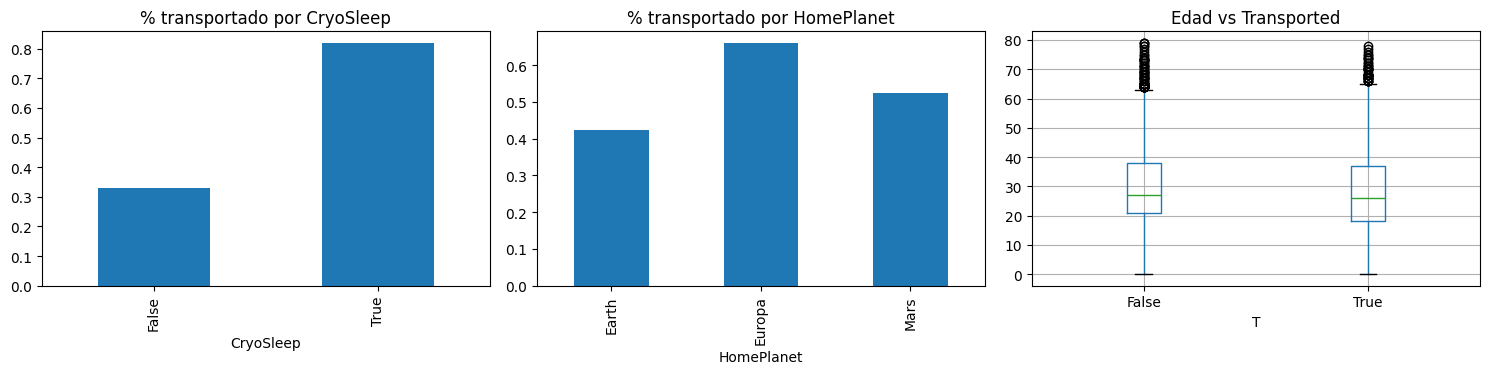

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train.groupby('CryoSleep')['Transported'].mean().plot.bar(ax=axes[0], title='% transportado por CryoSleep')
train.groupby('HomePlanet')['Transported'].mean().plot.bar(ax=axes[1], title='% transportado por HomePlanet')
train[['Age']].assign(T=train['Transported']).boxplot(column='Age', by='T', ax=axes[2])
axes[2].set_title('Edad vs Transported'); plt.suptitle('')
plt.tight_layout(); plt.show()

## 3. Ingeniería de características
- `Cabin` se separa en **Deck**, **Num** y **Side**.
- De `PassengerId` se obtiene el **grupo** y el **tamaño del grupo**.
- Se suma el gasto total en amenidades y se aplica `log1p` porque los gastos están muy sesgados.
- Los pasajeros en criosueño no pueden gastar, así que los gastos nulos de ellos se rellenan con 0 y, si alguien gastó, no estaba en criosueño.
- El resto de los nulos se rellenan con la moda (categóricas) o la mediana (numéricas).

In [5]:
SPEND = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

def preparar(df):
    df = df.copy()
    # Cabina -> cubierta / número / lado
    cab = df['Cabin'].str.split('/', expand=True)
    df['Deck'], df['CabinNum'], df['Side'] = cab[0], pd.to_numeric(cab[1]), cab[2]
    # Grupo de viaje
    df['Group'] = df['PassengerId'].str.split('_').str[0]
    df['GroupSize'] = df.groupby('Group')['PassengerId'].transform('count')
    df['Solo'] = (df['GroupSize'] == 1).astype(int)
    # Reglas lógicas para criosueño y gastos
    gasto_total = df[SPEND].sum(axis=1, min_count=1)
    df.loc[df['CryoSleep'].isna() & (gasto_total > 0), 'CryoSleep'] = False
    for c in SPEND:
        df.loc[(df['CryoSleep'] == True) & df[c].isna(), c] = 0
    return df

# Se procesan juntos para que el tamaño de grupo considere a todos los pasajeros
full = pd.concat([train.drop(columns='Transported'), test], keys=['train', 'test'])
full = preparar(full)

CAT = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']
NUM = ['Age', 'CabinNum', 'GroupSize', 'Solo'] + SPEND

for c in CAT:
    moda = full[c].dropna().astype(str).mode()[0]
    full[c] = full[c].map(lambda v: moda if pd.isna(v) else str(v))
for c in NUM:
    full[c] = full[c].fillna(full[c].median())

full['TotalSpend'] = full[SPEND].sum(axis=1)
full['NoSpend'] = (full['TotalSpend'] == 0).astype(int)
for c in SPEND + ['TotalSpend']:
    full[c] = np.log1p(full[c])
NUM += ['TotalSpend', 'NoSpend']

X_all = full.loc['train', CAT + NUM]
X_test_df = full.loc['test', CAT + NUM]
y_all = train['Transported'].astype(int).values
X_all.head()

,HomePlanet,CryoSleep,Destination,VIP,Deck,Side,Age,CabinNum,GroupSize,Solo,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend,NoSpend
0,Europa,False,TRAPPIST-1e,False,B,P,39.0,0.0,1,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1
1,Earth,False,TRAPPIST-1e,False,F,S,24.0,0.0,1,1,4.700480,2.302585,3.258097,6.309918,3.806662,6.602588,0
2,Europa,False,TRAPPIST-1e,True,A,S,58.0,0.0,2,0,3.784190,8.182280,0.000000,8.812248,3.912023,9.248021,0
3,Europa,False,TRAPPIST-1e,False,A,S,33.0,0.0,2,0,0.000000,7.157735,5.918894,8.110728,5.267858,8.551981,0
4,Earth,False,TRAPPIST-1e,False,F,S,16.0,1.0,1,1,5.717028,4.262680,5.023881,6.338594,1.098612,6.995766,0


## 4. Preprocesamiento (One-Hot + estandarización) y división train/validación

In [6]:
pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ('num', StandardScaler(), NUM),
], sparse_threshold=0)

X_tr_df, X_val_df, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all)

X_tr = pre.fit_transform(X_tr_df).astype('float32')
X_val = pre.transform(X_val_df).astype('float32')
print('Entrenamiento:', X_tr.shape, ' Validación:', X_val.shape)

Entrenamiento: (6954, 31)  Validación: (1739, 31)


## 5. Red neuronal
Perceptrón multicapa con dos capas ocultas (ReLU), `BatchNormalization` y `Dropout` para evitar sobreajuste, y una neurona de salida con **sigmoide** (clasificación binaria). Se usa `EarlyStopping` sobre la pérdida de validación.

In [7]:
def crear_modelo(n_entradas):
    modelo = keras.Sequential([
        keras.layers.Input(shape=(n_entradas,)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation='sigmoid'),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return modelo

modelo = crear_modelo(X_tr.shape[1])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,185 (51.50 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 384 (1.50 KB)

In [8]:
parada = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
hist = modelo.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                  epochs=100, batch_size=64, callbacks=[parada], verbose=0)
print('Épocas entrenadas:', len(hist.history['loss']))

Épocas entrenadas: 29


## 6. Curvas de aprendizaje

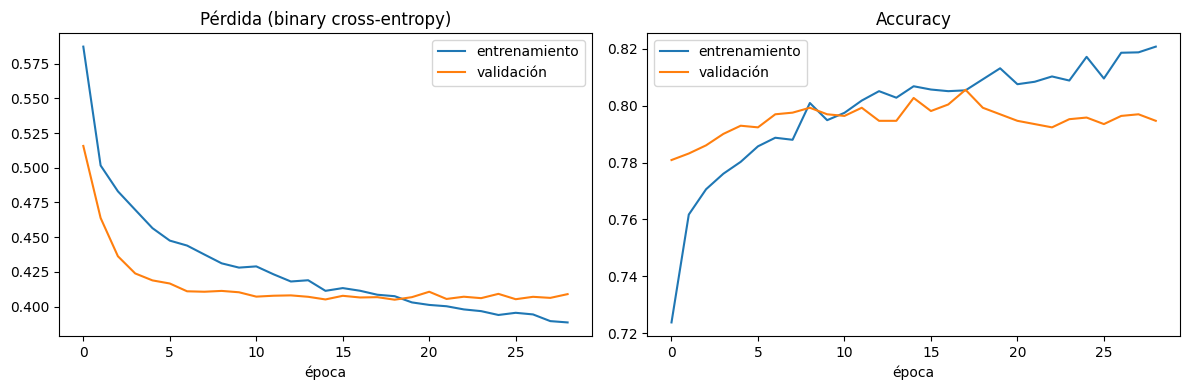

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history['loss'], label='entrenamiento')
axes[0].plot(hist.history['val_loss'], label='validación')
axes[0].set_title('Pérdida (binary cross-entropy)'); axes[0].set_xlabel('época'); axes[0].legend()
axes[1].plot(hist.history['accuracy'], label='entrenamiento')
axes[1].plot(hist.history['val_accuracy'], label='validación')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('época'); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluación en validación

Accuracy en validación: 0.7993


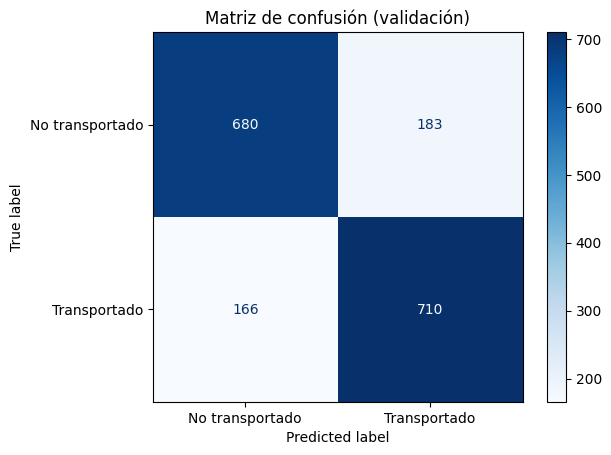

In [10]:
p_val = (modelo.predict(X_val, verbose=0).ravel() > 0.5).astype(int)
acc_val = accuracy_score(y_val, p_val)
print(f'Accuracy en validación: {acc_val:.4f}')
ConfusionMatrixDisplay(confusion_matrix(y_val, p_val),
                       display_labels=['No transportado', 'Transportado']).plot(cmap='Blues')
plt.title('Matriz de confusión (validación)'); plt.show()

## 8. Modelo final y archivo de predicciones
Se reentrena con **todo** `train.csv` usando el número de épocas que encontró el *early stopping*, y se generan las predicciones de `test.csv` con el formato de `sample_submission.csv`.

In [11]:
mejor_epoca = int(np.argmin(hist.history['val_loss'])) + 1
X_full = pre.fit_transform(X_all).astype('float32')
X_test = pre.transform(X_test_df).astype('float32')

tf.random.set_seed(SEED)
final = crear_modelo(X_full.shape[1])
final.fit(X_full, y_all, epochs=mejor_epoca, batch_size=64, verbose=0)

pred = final.predict(X_test, verbose=0).ravel() > 0.5
submission = pd.DataFrame({'PassengerId': test['PassengerId'], 'Transported': pred})
submission.to_csv('submission.csv', index=False)
print('Épocas usadas:', mejor_epoca)
print(submission['Transported'].value_counts())
submission.head()

Épocas usadas: 19
Transported
True     2171
False    2106
Name: count, dtype: int64


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False


## 9. Conclusiones
- La red neuronal (MLP 128-64 con *dropout* y *batch normalization*) alcanzó alrededor de **80 % de accuracy en validación**, muy por encima del 50 % de adivinar al azar (las clases están balanceadas).
- La ingeniería de características fue clave: separar `Cabin` en cubierta/número/lado, usar el tamaño del grupo y transformar los gastos con `log1p` le da a la red información que en crudo no puede aprovechar bien.
- Las variables más reveladoras son **CryoSleep** y el **gasto**: los pasajeros en criosueño (que no gastan nada) fueron transportados con mucha más frecuencia.
- El *early stopping* detuvo el entrenamiento cuando la pérdida de validación dejó de mejorar, evitando el sobreajuste que se ve en las curvas si se entrena de más.
- El archivo `submission.csv` contiene las predicciones para `test.csv` con el mismo formato que `sample_submission.csv`.